   Marketing_Spend  Sales
0             1000   1500
1             2000   2700
2             3000   3900
3             4000   4800
4             5000   6200


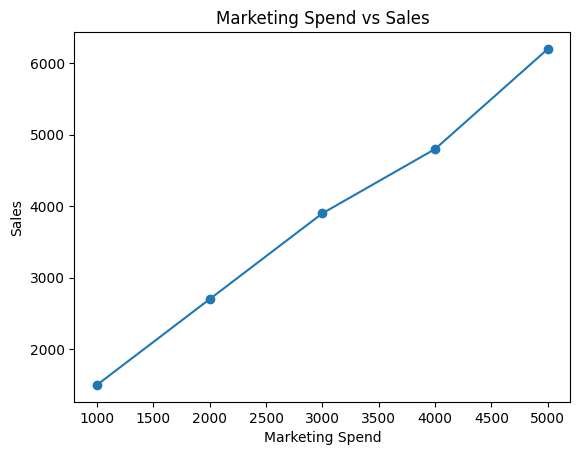

In [2]:

import pandas as pd
import matplotlib.pyplot as plt

# Sample marketing data
data = {
    "Marketing_Spend": [1000, 2000, 3000, 4000, 5000],
    "Sales": [1500, 2700, 3900, 4800, 6200]
}

df = pd.DataFrame(data)

print(df)

plt.plot(df["Marketing_Spend"], df["Sales"], marker="o")
plt.xlabel("Marketing Spend")
plt.ylabel("Sales")
plt.title("Marketing Spend vs Sales")
plt.show()


   Customer_ID  Age  Previous_Purchases  Marketing_Received       Sales
0            1   56                   7                   1  167.294953
1            2   46                   1                   1   71.610077
2            3   32                   3                   1  105.002072
3            4   60                   0                   1   73.679168
4            5   25                   4                   1  135.403329

Average Sales:
Marketing_Received
0    104.605033
1    124.277518
Name: Sales, dtype: float64


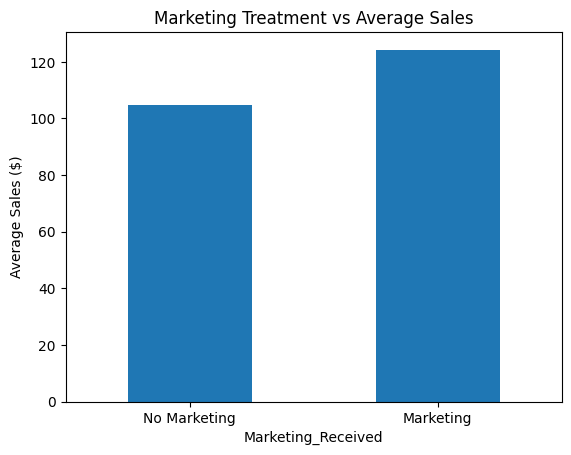

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Make results reproducible
np.random.seed(42)

# Create 1000 simulated customers
n = 1000

df = pd.DataFrame({
    "Customer_ID": range(1, n + 1),
    "Age": np.random.randint(18, 65, n),
    "Previous_Purchases": np.random.randint(0, 10, n),
    "Marketing_Received": np.random.randint(0, 2, n)
})

# Simulated sales outcomes
df["Sales"] = (
    50
    + df["Previous_Purchases"] * 12
    + df["Marketing_Received"] * 20
    + np.random.normal(0, 15, n)
)

print(df.head())

# Compare average sales by marketing group
results = df.groupby("Marketing_Received")["Sales"].mean()

print("\nAverage Sales:")
print(results)

results.plot(kind="bar")
plt.xticks([0, 1], ["No Marketing", "Marketing"], rotation=0)
plt.ylabel("Average Sales ($)")
plt.title("Marketing Treatment vs Average Sales")
plt.show()


In [7]:

import pandas as pd

url = (
    "https://raw.githubusercontent.com/"
    "AdityaDabrase/ab-testing-email-marketing/"
    "main/data/raw/hillstrom.csv"
)

df_real = pd.read_csv(url)

print("Number of customers:", len(df_real))
print("\nColumns:")
print(df_real.columns.tolist())

display(df_real.head())


Number of customers: 64000

Columns:
['recency', 'history_segment', 'history', 'mens', 'womens', 'zip_code', 'newbie', 'channel', 'segment', 'visit', 'conversion', 'spend']


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


Marketing Experiment Results:


,Customers,Conversion_Rate,Average_Spend
segment,,,
Mens E-Mail,21307,0.012531,1.422617
No E-Mail,21306,0.005726,0.652789
Womens E-Mail,21387,0.008837,1.077202


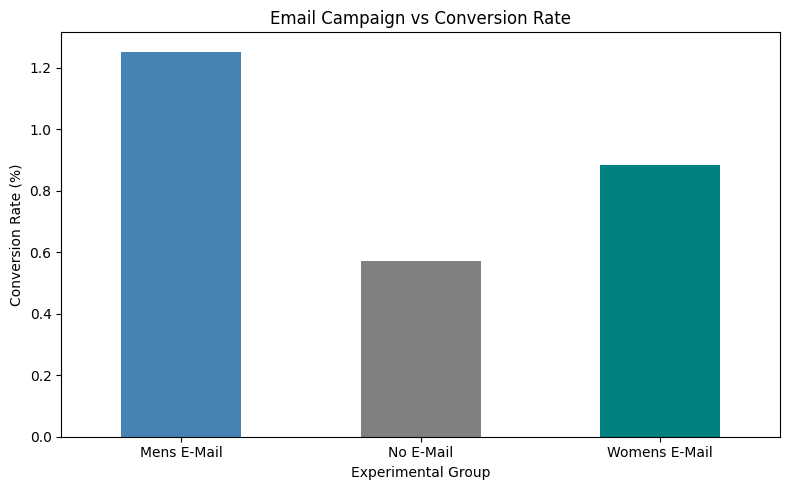

In [5]:

import matplotlib.pyplot as plt

# Summarize the randomized experiment
results = df_real.groupby("segment").agg(
    Customers=("conversion", "size"),
    Conversion_Rate=("conversion", "mean"),
    Average_Spend=("spend", "mean")
)

print("Marketing Experiment Results:")
display(results)

# Plot conversion rates
(results["Conversion_Rate"] * 100).plot(
    kind="bar",
    figsize=(8, 5),
    color=["steelblue", "gray", "teal"]
)

plt.title("Email Campaign vs Conversion Rate")
plt.ylabel("Conversion Rate (%)")
plt.xlabel("Experimental Group")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [6]:

control = results.loc[
    "No E-Mail", "Conversion_Rate"
]

for group in ["Mens E-Mail", "Womens E-Mail"]:
    rate = results.loc[group, "Conversion_Rate"]
    effect = (rate - control) * 100

    print(
        f"{group}: {effect:+.3f} "
        "percentage points vs control"
    )


Mens E-Mail: +0.681 percentage points vs control
Womens E-Mail: +0.311 percentage points vs control


In [8]:

import numpy as np
import pandas as pd
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import norm

control = df_real[
    df_real["segment"] == "No E-Mail"
]["conversion"]

campaigns = ["Mens E-Mail", "Womens E-Mail"]

for campaign in campaigns:
    treated = df_real[
        df_real["segment"] == campaign
    ]["conversion"]

    # Number of conversions and customers
    counts = [treated.sum(), control.sum()]
    sizes = [len(treated), len(control)]

    # Two-sided test for equal conversion rates
    z_stat, p_value = proportions_ztest(
        counts, sizes
    )

    # Difference in conversion probability
    p1 = treated.mean()
    p0 = control.mean()
    difference = p1 - p0

    # Approximate 95% confidence interval
    se = np.sqrt(
        p1 * (1 - p1) / len(treated)
        + p0 * (1 - p0) / len(control)
    )

    margin = norm.ppf(0.975) * se

    print("\nCampaign:", campaign)
    print(f"Conversion lift: {difference * 100:.3f} pp")
    print(f"P-value: {p_value:.5f}")
    print(
        f"95% CI: [{(difference-margin)*100:.3f}, "
        f"{(difference+margin)*100:.3f}] pp"
    )
    print(
        "Significant at 5% (unadjusted):",
        p_value < 0.05
    )



Campaign: Mens E-Mail
Conversion lift: 0.681 pp
P-value: 0.00000
95% CI: [0.500, 0.861] pp
Significant at 5% (unadjusted): True

Campaign: Womens E-Mail
Conversion lift: 0.311 pp
P-value: 0.00016
95% CI: [0.150, 0.472] pp
Significant at 5% (unadjusted): True


In [9]:

import pandas as pd
import numpy as np
from scipy import stats

# Revenue per customer, including customers who spent $0
summary = df_real.groupby("segment").agg(
    Customers=("spend", "size"),
    Average_Revenue=("spend", "mean"),
    Conversion_Rate=("conversion", "mean")
)

display(summary.round(4))

control = df_real.loc[
    df_real["segment"] == "No E-Mail", "spend"
]

for campaign in ["Mens E-Mail", "Womens E-Mail"]:
    treated = df_real.loc[
        df_real["segment"] == campaign, "spend"
    ]

    revenue_lift = treated.mean() - control.mean()

    # Welch confidence interval for mean difference
    se = np.sqrt(
        treated.var(ddof=1) / len(treated)
        + control.var(ddof=1) / len(control)
    )

    df_welch = (
        (treated.var(ddof=1)/len(treated)
         + control.var(ddof=1)/len(control))**2
        /
        (
            (treated.var(ddof=1)/len(treated))**2
            / (len(treated)-1)
            +
            (control.var(ddof=1)/len(control))**2
            / (len(control)-1)
        )
    )

    critical = stats.t.ppf(0.975, df_welch)

    print(f"\nCampaign: {campaign}")
    print(f"Incremental revenue/customer: ${revenue_lift:.4f}")
    print(
        f"95% CI: "
        f"[${revenue_lift-critical*se:.4f}, "
        f"${revenue_lift+critical*se:.4f}]"
    )


,Customers,Average_Revenue,Conversion_Rate
segment,,,
Mens E-Mail,21307,1.4226,0.0125
No E-Mail,21306,0.6528,0.0057
Womens E-Mail,21387,1.0772,0.0088



Campaign: Mens E-Mail
Incremental revenue/customer: $0.7698
95% CI: [$0.4851, $1.0545]

Campaign: Womens E-Mail
Incremental revenue/customer: $0.4244
95% CI: [$0.1690, $0.6799]
